# Cross-hospital TB screening from chest X-rays
**Maths project · Shenzhen → Montgomery County**

Can PCA compress gradient features while retaining sensitivity on a second hospital? Can a threshold chosen to reach 90% sensitivity in Shenzhen do the same in Montgomery? Run all cells in a CPU Colab session. The last cell packages the results. For Kaggle Notebooks, attach the linked dataset as input. For a manually downloaded dataset, extract the ZIP and set DATA_ROOT below.

**Paper extension.** Surulivelu et al. describe 70 test images, while the counts in Figure 8 total 140. Their lung-region masks also answer a different question from lesion localization. Here every prediction has a named split and denominator. The outcome is the dataset’s image-level label: normal (0) or TB-consistent abnormality (1).

[Base paper](https://www.sciencedirect.com/science/article/pii/S1746809425014399) · [Kaggle dataset](https://www.kaggle.com/datasets/nikhilpandey360/chest-xray-masks-and-labels) · [Original cohort descriptions](https://pmc.ncbi.nlm.nih.gov/articles/PMC4256233/)

In [ ]:
from pathlib import Path
import hashlib
import json
import re
import shutil
import subprocess
import sys
import tempfile

import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

DATA_ROOT = None  # Example: "/content/extracted-dataset"
DATASET = "nikhilpandey360/chest-xray-masks-and-labels"
SEED = 42
TARGET = 0.90
VARIANCE = 0.95
RIDGE = 0.02
out = Path(tempfile.mkdtemp(prefix="tb_results_", dir=Path.cwd()))

if DATA_ROOT is None:
    attached = list(Path("/kaggle/input").glob("**/chest-xray-masks-and-labels"))
    if len(attached) == 1:
        root = attached[0]
    else:
        try:
            import kagglehub
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        root = Path(kagglehub.dataset_download(DATASET))
else:
    root = Path(DATA_ROOT)
print("Dataset folder:", root)
print("Results folder:", out)

100%|██████████| 9.58G/9.58G [01:45<00:00, 97.1MB/s]

Extracting files...


Dataset folder: /root/.cache/kagglehub/datasets/nikhilpandey360/chest-xray-masks-and-labels/versions/1
Results folder: /content/tb_results_11_8d87f


## 1. Audit the records and freeze the split
CHNCXR and MCUCXR identify the two source collections. The final filename digit is the label. Use the hospital and case number as the available patient identifier proxy. Select radiographs only; mask availability must not determine eligibility. Keep byte-identical copies of the same case once and stop on ambiguous duplicates. Different encodings of the same patient under different IDs are a residual limitation.

In [ ]:
def build_manifest(root):
    image_dir = root / "Lung Segmentation" / "CXR_png"
    if not image_dir.is_dir():
        raise FileNotFoundError(f"X-ray folder not found: {image_dir}")

    pattern = re.compile(r"(CHNCXR|MCUCXR)_(\d+)_([01])\.png", re.I)
    sites = {"CHNCXR": "Shenzhen", "MCUCXR": "Montgomery"}

    rows = []
    seen_cases = {}
    seen_bytes = {}
    copies = 0

    for path in sorted(image_dir.glob("*.png")):
        match = pattern.fullmatch(path.name)
        if not match or not path.is_file():
            continue

        prefix, number, label = match.groups()
        prefix = prefix.upper()
        label = int(label)
        case = f"{prefix}_{int(number):04d}"
        digest = hashlib.sha256(path.read_bytes()).hexdigest()

        if case in seen_cases:
            if seen_cases[case] != (digest, label):
                raise ValueError(f"Conflicting copies for {case} in {image_dir}")
            copies += 1
            continue

        if digest in seen_bytes:
            raise ValueError(
                f"Same image under two case IDs: {case} and {seen_bytes[digest]}"
            )

        seen_cases[case] = (digest, label)
        seen_bytes[digest] = case
        rows.append((case, sites[prefix], label, str(path.relative_to(root)), digest))

    frame = pd.DataFrame(rows, columns=["case", "site", "y", "file", "sha256"])
    if frame.empty:
        raise ValueError(f"No matching X-ray filenames found in {image_dir}")

    counts = pd.crosstab(frame["site"], frame["y"]).reindex(
        index=["Shenzhen", "Montgomery"], columns=[0, 1], fill_value=0
    )
    if (counts < 2).any().any():
        raise ValueError(f"Too few cases for a hospital or label:\n{counts}")

    print("Identical extra copies skipped:", copies)
    return frame


def freeze_split(frame):
    frame = frame.copy()
    frame["split"] = np.where(frame["site"] == "Shenzhen", "train", "external")
    rng = np.random.default_rng(SEED)

    shenzhen = frame[frame["site"] == "Shenzhen"]
    for _, group in shenzhen.groupby("y"):
        count = max(1, min(len(group) - 1, round(0.25 * len(group))))
        validation_ids = rng.choice(group.index, size=count, replace=False)
        frame.loc[validation_ids, "split"] = "validation"

    return frame


manifest = freeze_split(build_manifest(root))
manifest.to_csv(out / "manifest.csv", index=False)

display(pd.crosstab(
    [manifest["site"], manifest["split"]],
    manifest["y"],
    margins=True
))

Identical extra copies skipped: 0


y                        0    1  All
site       split                    
Montgomery external     80   58  138
Shenzhen   train       244  252  496
           validation   82   84  166
All                    406  394  800

In [ ]:
for path in sorted(root.rglob("CHNCXR_0025*.png")):
    print(path.relative_to(root))

Lung Segmentation/CXR_png/CHNCXR_0025_0.png
Lung Segmentation/test/CHNCXR_0025_0.png
data/Lung Segmentation/CXR_png/CHNCXR_0025_0.png
data/Lung Segmentation/test/CHNCXR_0025_0.png


## 2. Turn each X-ray into a feature vector
Preserve image aspect ratio, use a fixed 128 × 128 canvas and normalize the grayscale range per image. Compute gradient magnitude and unsigned orientation, vote into nine bins within 16 × 16 cells, then normalize overlapping 2 × 2 cell blocks. This hard-binned HOG variant yields 1,764 features per image. All preprocessing rules are fixed before evaluation.

In [ ]:
def read_xray(path):
    with Image.open(path) as im:
        gray = im.convert("F") if im.mode in ("L", "I", "F") or im.mode.startswith("I;16") else im.convert("L").convert("F")
        small = ImageOps.contain(gray, (128, 128), method=Image.Resampling.BILINEAR)
        a = np.asarray(small, dtype=float)
    lo, hi = np.percentile(a, [1, 99])
    if hi <= lo:
        raise ValueError(f"Insufficient grayscale variation: {path}")
    a = np.clip((a - lo) / (hi - lo), 0, 1)
    h, w = a.shape
    canvas = np.zeros((128, 128))
    row, col = (128-h)//2, (128-w)//2
    canvas[row:row+h, col:col+w] = a
    return canvas

def hog_features(a):
    dy, dx = np.gradient(a)
    strength = np.hypot(dx, dy)
    bins = (np.degrees(np.arctan2(dy, dx)) % 180 / 20).astype(int) % 9
    row, col = np.indices(a.shape)
    index = ((row // 16) * 8 + col // 16) * 9 + bins
    hist = np.bincount(index.ravel(), weights=strength.ravel(), minlength=576).reshape(8, 8, 9)
    blocks = np.array([hist[r:r+2, c:c+2].ravel() for r in range(7) for c in range(7)])
    blocks /= np.maximum(np.linalg.norm(blocks, axis=1, keepdims=True), 1e-8)
    blocks = np.minimum(blocks, 0.2)
    blocks /= np.maximum(np.linalg.norm(blocks, axis=1, keepdims=True), 1e-8)
    return blocks.ravel()

def features(rows):
    return np.stack([hog_features(read_xray(root / path)) for path in rows.file])

train = manifest[manifest.split == "train"]
val = manifest[manifest.split == "validation"]
external = manifest[manifest.split == "external"]
Xtrain, Xval = features(train), features(val)
print("Training feature matrix:", Xtrain.shape)

Training feature matrix: (496, 1764)


## 3. Fit two models on the same Shenzhen cases
Standardize using training means and standard deviations. For the PCA arm, decompose the standardized training matrix as \(X=U\Sigma V^\top\). Keep the smallest \(k\) such that \(\sum_{j=1}^k \sigma_j^2 / \sum_j \sigma_j^2 \ge 0.95\). Project new images using those same directions.

Both arms minimize mean logistic loss plus \(0.02\lVert w\rVert_2^2/2\); the intercept is unpenalized. This fixes regularization and isolates the effect of discarding low-variance directions. Retaining 95% of variance does not guarantee retaining 95% of the information relevant to TB.

In [ ]:
from sklearn.linear_model import LogisticRegression

mean, scale = Xtrain.mean(axis=0), Xtrain.std(axis=0)
scale[scale < 1e-8] = 1
A, B = (Xtrain - mean)/scale, (Xval - mean)/scale
_, singular, vt = np.linalg.svd(A, full_matrices=False)
energy = np.cumsum(singular**2) / np.sum(singular**2)
k = int(np.searchsorted(energy, VARIANCE)) + 1
projection = vt[:k].T

def transform(z, model):
    return z if model == "HOG" else z @ projection

models = {}
for name in ["HOG", "HOG + PCA"]:
    model = LogisticRegression(C=1/(len(train)*RIDGE), solver="lbfgs", max_iter=2000)
    models[name] = model.fit(transform(A, name), train.y)
print(f"PCA retained {k} of {A.shape[1]} input features ({energy[k-1]:.2%} training variance).")

PCA retained 249 of 1764 input features (95.01% training variance).


## 4. Choose the decision threshold using Shenzhen validation cases
A score at or above the threshold flags a case. Maximize specificity subject to validation sensitivity ≥ 90%. Break ties by higher sensitivity, then by higher threshold. This target is an experiment setting. Keep the default 0.5 threshold as a comparison. Freeze both models and both thresholds before scoring Montgomery.

In [ ]:
def confusion(y, score, threshold):
    y = np.asarray(y, dtype=bool)
    pos = np.asarray(score) >= threshold
    return tuple(int(np.sum(v)) for v in (y & pos, y & ~pos, ~y & ~pos, ~y & pos))

def pick_threshold(y, score):
    candidates = []
    for t in np.unique(score):
        tp, fn, tn, fp = confusion(y, score, t)
        sens, spec = tp/(tp+fn), tn/(tn+fp)
        if sens >= TARGET:
            candidates.append((spec, sens, float(t)))
    return max(candidates)[2]

def scores(x, name):
    return models[name].predict_proba(transform(x, name))[:, 1]

validation_scores = {name: scores(B, name) for name in models}
cutoffs = {name: pick_threshold(val.y, s) for name, s in validation_scores.items()}
print("Locked thresholds:", cutoffs)

Locked thresholds: {'HOG': 0.02431193970871041, 'HOG + PCA': 0.036642788799016876}


## 5. Evaluate the frozen models once on Montgomery County
Compute sensitivity = TP/(TP+FN) and specificity = TN/(TN+FP), with 95% Wilson intervals. A missed TB-labeled case is a false negative. A normal case flagged for review is a false positive. Compare PCA and baseline on the same cases using paired, class-stratified bootstrap intervals; these intervals condition on the trained models and chosen thresholds.

In [ ]:
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay

def wilson(success, total):
    z = 1.959964
    p = success / total
    denom = 1 + z*z/total
    center = (p + z*z/(2*total)) / denom
    half = z*np.sqrt(p*(1-p)/total + z*z/(4*total**2)) / denom
    return max(0, center-half), min(1, center+half)

Z = (features(external) - mean)/scale
external_scores = {name: scores(Z, name) for name in models}
summaries, predictions = [], []
for samples, score_map in [(val, validation_scores), (external, external_scores)]:
    for name, score in score_map.items():
        for rule, threshold in [("default", 0.5), ("selected", cutoffs[name])]:
            tp, fn, tn, fp = confusion(samples.y, score, threshold)
            slo, shi = wilson(tp, tp+fn)
            clo, chi = wilson(tn, tn+fp)
            summaries.append(dict(split=samples.split.iloc[0], model=name, rule=rule,
                threshold=threshold, n=len(samples), TP=tp, FN=fn, TN=tn, FP=fp,
                sensitivity=tp/(tp+fn), sens_low=slo, sens_high=shi, specificity=tn/(tn+fp),
                spec_low=clo, spec_high=chi, auc=roc_auc_score(samples.y, score)))
            predictions.append(samples[["case","site","split","y"]].assign(
                model=name, rule=rule, threshold=threshold, score=score, predicted=(score>=threshold).astype(int)))
results = pd.DataFrame(summaries)
results.to_csv(out / "metrics.csv", index=False)
pd.concat(predictions).to_csv(out / "predictions.csv", index=False)
display(results.round(3))

rng = np.random.default_rng(SEED)
differences = []
for y, metric in [(1, "sensitivity"), (0, "specificity")]:
    select = external.y.to_numpy() == y
    correct = {name: ((s[select] >= cutoffs[name]) == bool(y)).astype(int)
               for name, s in external_scores.items()}
    delta = correct["HOG + PCA"] - correct["HOG"]
    boot = rng.choice(delta, (5000, len(delta)), replace=True).mean(axis=1)
    low, high = np.quantile(boot, [0.025, 0.975])
    differences.append(dict(metric=metric, PCA_minus_HOG=delta.mean(), low=low, high=high))
diff = pd.DataFrame(differences)
diff.to_csv(out / "paired_differences.csv", index=False)
display(diff.round(3))

,split,model,rule,threshold,n,TP,FN,TN,FP,sensitivity,sens_low,sens_high,specificity,spec_low,spec_high,auc
0,validation,HOG,default,0.500,166,61,23,73,9,0.726,0.623,0.810,0.890,0.804,0.941,0.864
1,validation,HOG,selected,0.024,166,76,8,40,42,0.905,0.823,0.951,0.488,0.383,0.594,0.864
2,validation,HOG + PCA,default,0.500,166,59,25,71,11,0.702,0.598,0.790,0.866,0.776,0.923,0.874
3,validation,HOG + PCA,selected,0.037,166,76,8,49,33,0.905,0.823,0.951,0.598,0.489,0.697,0.874
4,external,HOG,default,0.500,138,23,35,58,22,0.397,0.281,0.525,0.725,0.619,0.811,0.616
5,external,HOG,selected,0.024,138,39,19,33,47,0.672,0.544,0.779,0.412,0.311,0.522,0.616
6,external,HOG + PCA,default,0.500,138,17,41,61,19,0.293,0.192,0.420,0.762,0.659,0.842,0.588
7,external,HOG + PCA,selected,0.037,138,34,24,42,38,0.586,0.458,0.704,0.525,0.417,0.631,0.588


,metric,PCA_minus_HOG,low,high
0,sensitivity,-0.086,-0.190,0.017
1,specificity,0.112,0.025,0.200


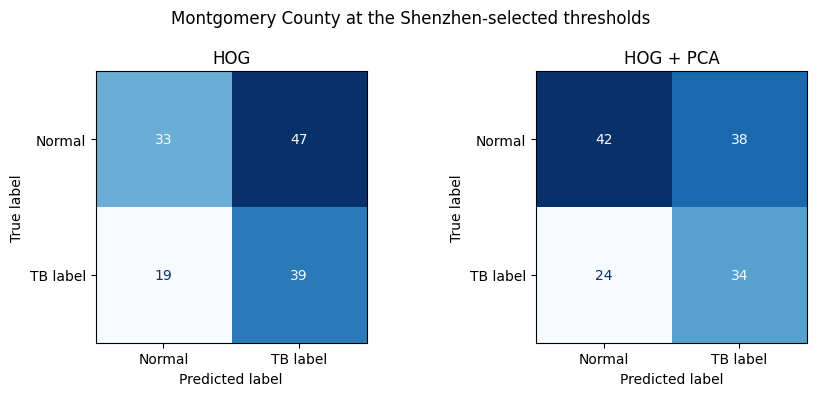

Feature reduction: 1764 to 249 (85.9% fewer).
HOG: sensitivity 90.5% in Shenzhen validation and 67.2% in Montgomery; 19 missed of 58 positive cases, 47 false alarms of 80 normal cases.
HOG + PCA: sensitivity 90.5% in Shenzhen validation and 58.6% in Montgomery; 24 missed of 58 positive cases, 38 false alarms of 80 normal cases.


/content/tb_results_11_8d87f.zip

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, score) in zip(axes, external_scores.items()):
    ConfusionMatrixDisplay.from_predictions(external.y, score >= cutoffs[name],
        labels=[0,1], display_labels=["Normal", "TB label"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.suptitle("Montgomery County at the Shenzhen-selected thresholds")
fig.tight_layout()
fig.savefig(out / "external_confusion.png", dpi=160)
plt.show()

print(f"Feature reduction: {A.shape[1]} to {k} ({1-k/A.shape[1]:.1%} fewer).")
for name in models:
    locked = results[(results.model == name) & (results.rule == "selected")].set_index("split")
    v, e = locked.loc["validation"], locked.loc["external"]
    print(f"{name}: sensitivity {v.sensitivity:.1%} in Shenzhen validation and "
          f"{e.sensitivity:.1%} in Montgomery; {int(e.FN)} missed of {int(e.TP+e.FN)} "
          f"positive cases, {int(e.FP)} false alarms of {int(e.TN+e.FP)} normal cases.")
import sklearn
import PIL
settings = dict(dataset=DATASET, dataset_path=str(root), seed=SEED, target=TARGET,
                regularization=RIDGE, variance_target=VARIANCE, components=k,
                original_features=A.shape[1], thresholds=cutoffs, python=sys.version,
                numpy=np.__version__, pandas=pd.__version__, pillow=PIL.__version__, sklearn=sklearn.__version__)
(out / "settings.json").write_text(json.dumps(settings, indent=2))
archive = shutil.make_archive(str(out), "zip", out)
from IPython.display import FileLink
display(FileLink(Path(archive).name))
# In Colab, the ZIP is also available in the Files panel.

In [ ]:
from google.colab import files
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>